# Learning a contact tangent plane

We will apply a known force to a point constrained to a surface, infer its admissible velocity plane, and predict its response to another force. Then we will ask whether a **distribution over planes** improves that prediction or describes its uncertainty better than an inexpensive Gaussian filter.

The connection to [Learning Null Space Projections](https://doi.org/10.1109/ICRA.2015.7139551) is direct: the constraint is $J_c\dot p=0$, and $P_{\ker J_c}$ projects free motion into the allowed null space. Here $J_c=n^\top$ is one unknown surface-normal constraint. The Bayesian state represents uncertainty about this same null space. This is a separate mechanical study, not a reproduction of that paper's algorithm.

This notebook follows **one preassigned trajectory**, then checks the conclusions on 64 independent trajectories per condition. Detailed scans are linked at the end. The original contact pilot and the other notebooks are preserved.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'lib').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from lib.plotting import plt
from lib.contact_tracking_evidence import check_evidence
from lib.contact_story import (contact_scene, tracking_scene, posterior_scene,
    response_comparison, paired_prediction_errors)
OUT = ROOT / 'results/contact_tracking'
gate = check_evidence(ROOT)
frozen = json.loads((OUT / 'mean/selected.json').read_text())
cfg = frozen['config']
assert plt.rcParams['text.usetex'] and plt.rcParams['figure.dpi'] == 200
def show(fig):
    display(fig)
    plt.close(fig)


## 1. What does the robot measure?

For a maintained contact with unit normal $n(p)$ and known isotropic viscous resistance $dI$, the mechanical solver enforces
$$d\dot p=F+n\lambda,\qquad n^\top\dot p=0.$$
Consequently $\dot p=P(F/d)$ with $P=I-nn^\top$. The filter receives the known free velocity $v=F/d$ and measured velocity $u=\dot p+e$, where $e\sim N(0,\sigma^2 I)$.

Below we generate the small sphere trajectory, with $R=5$ cm, $d=10$ N s/m, $\sigma=1$ mm/s and sampling interval $0.05$ s. Black positions and true normals are available to the simulator and scoring code only. Estimators receive **force and noisy velocity**, without geometric normals or positions. This is an ideal bilateral guide; it does not include contact loss or friction.

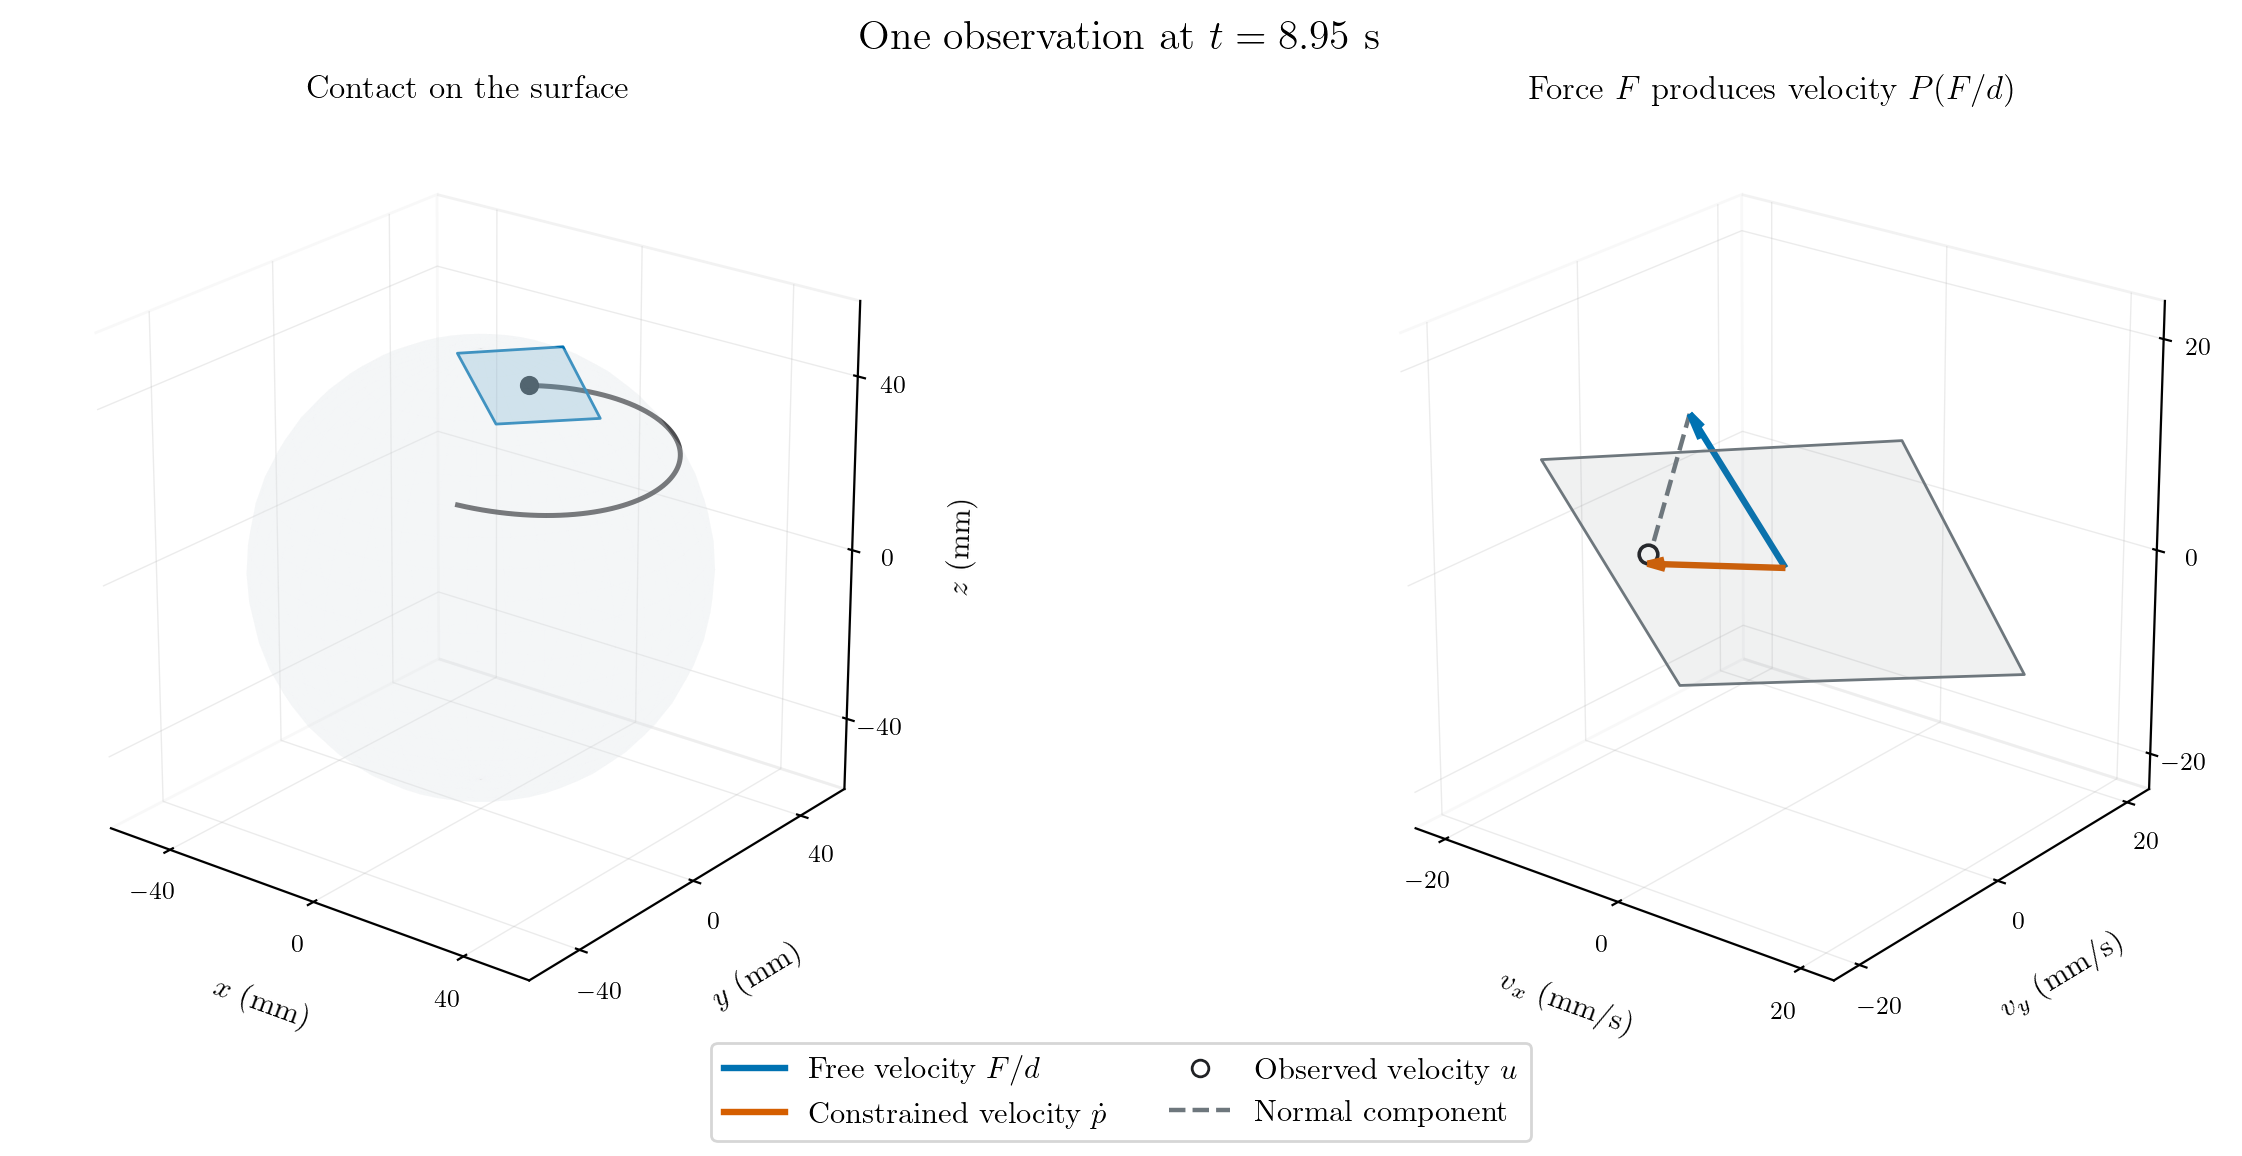

In [2]:
from lib.contact_tracking import plant_data
# Trajectory 0 and observation 180 were fixed before opening test results.
data = plant_data(cfg, cfg['test_seed'], 0, 'sphere_small')
j = 179
show(contact_scene(data, j, path=OUT / 'figures/01_mechanics'))


The blue arrow is the velocity the same force would produce without the constraint. The orange arrow is the mechanically allowed velocity. Their difference lies along the normal. The open circle shows one noisy measurement. This is the regression problem we must solve; the surface geometry is not supplied to the learner.

## 2. Fit the unknown null space

For a rank-two orthogonal projector, identifying the plane is constrained regression:
$$\widehat P=\mathop{\arg\min}_{P=P^\top=P^2,\;\mathrm{tr}P=2}
  \sum_i w_i\|\tilde u_i-P\tilde v_i\|^2.$$
Here $\tilde u_i,\tilde v_i$ are past pairs rotated into the current prediction frame; with identity prediction they are the original observations. The weights $w_i$ retain or discard old likelihood terms. The Bingham mode solves exactly this same problem. Each observation adds
$$B_t=\frac{u_tv_t^\top+v_tu_t^\top-v_tv_t^\top}{2\sigma^2}.$$
The recursion transports or discards old evidence before adding $B_t$. Its modal plane is a point estimate; computing a posterior mean is a separate operation. The following code replays the practical policy chosen on independent validation data.

In [3]:
from lib.contact_tracking import make_tracker
spec = frozen['best_per_scope']['curved']['specification']
tracker = make_tracker(cfg, spec)
parameters, priors, planes = [], [], []
for u, v in zip(data['U'], data['V']):
    priors.append(tracker.predict())       # Uses observations through t-1.
    X = tracker.update(u, v=v)             # Only now read the current u_t.
    parameters.append(tracker.A.copy())
    planes.append(X @ X.T)
parameters, priors, planes = map(np.asarray, (parameters, priors, planes))
display(Markdown(f"We retain **{spec.get('beta',1):.0%}** of previous weighted likelihood per observation. "
    f"The selected forecast estimates rotation from planes **{spec.get('lag',0)} observations apart** "
    "and extrapolates it by one sampling interval. The mode is checked against transported weighted least squares."))


We retain **90%** of previous weighted likelihood per observation. The selected forecast estimates rotation from planes **32 observations apart** and extrapolates it by one sampling interval. The mode is checked against transported weighted least squares.

## 3. Old measurements describe old planes

On a sphere, $\dot n=\dot p/R$: even perfect velocity measurements refer to different tangent planes as the point moves. Retaining more data reduces noise but can increase lag.

We compare noisy and noiseless replays of the **same mechanics and forces**, keeping the likelihood variance fixed at $10^{-6}$ in both. Removing noise must not silently change the memory or update scale. The true-normal alignment control is an unavailable diagnostic and never selects a practical method.

In [4]:
mode_results = pd.read_csv(OUT / 'mean/metrics.csv')
diagnostic = mode_results.query("condition == 'sphere_small' and t == 600 and method == 'original'")
noisy = diagnostic.query("noise == 'on'").corrected_mse.mean()
noiseless = diagnostic.query("noise == 'off'").corrected_mse.mean()
display(Markdown(f"With the original memory, terminal query MSE is **{noisy*1e6:.3f} (mm/s)²** with noise "
    f"and **{noiseless*1e6:.3f} (mm/s)²** without it. Residual error without noise exposes stale-state bias."))


With the original memory, terminal query MSE is **1.085 (mm/s)²** with noise and **0.937 (mm/s)²** without it. Residual error without noise exposes stale-state bias.

A causal motion forecast estimates the plane's rotation from earlier fitted planes. It predicts the current plane **before** seeing its current velocity. Orange uses the validation-selected memory without rotating old evidence; blue uses the validation-selected causal motion policy. Both predictions use observations through $t-1$. Their difference includes the accumulated effect of their recursions, rather than only the last rotation.

The next figure compares orientations at a common centre, rather than pretending the past planes occurred at the same physical position. In the magnified view, $\theta_1,\theta_2$ are two perpendicular components of the smallest rotation from the true normal to the estimated normal. The origin is the true plane; distance from it is the angular error in degrees.

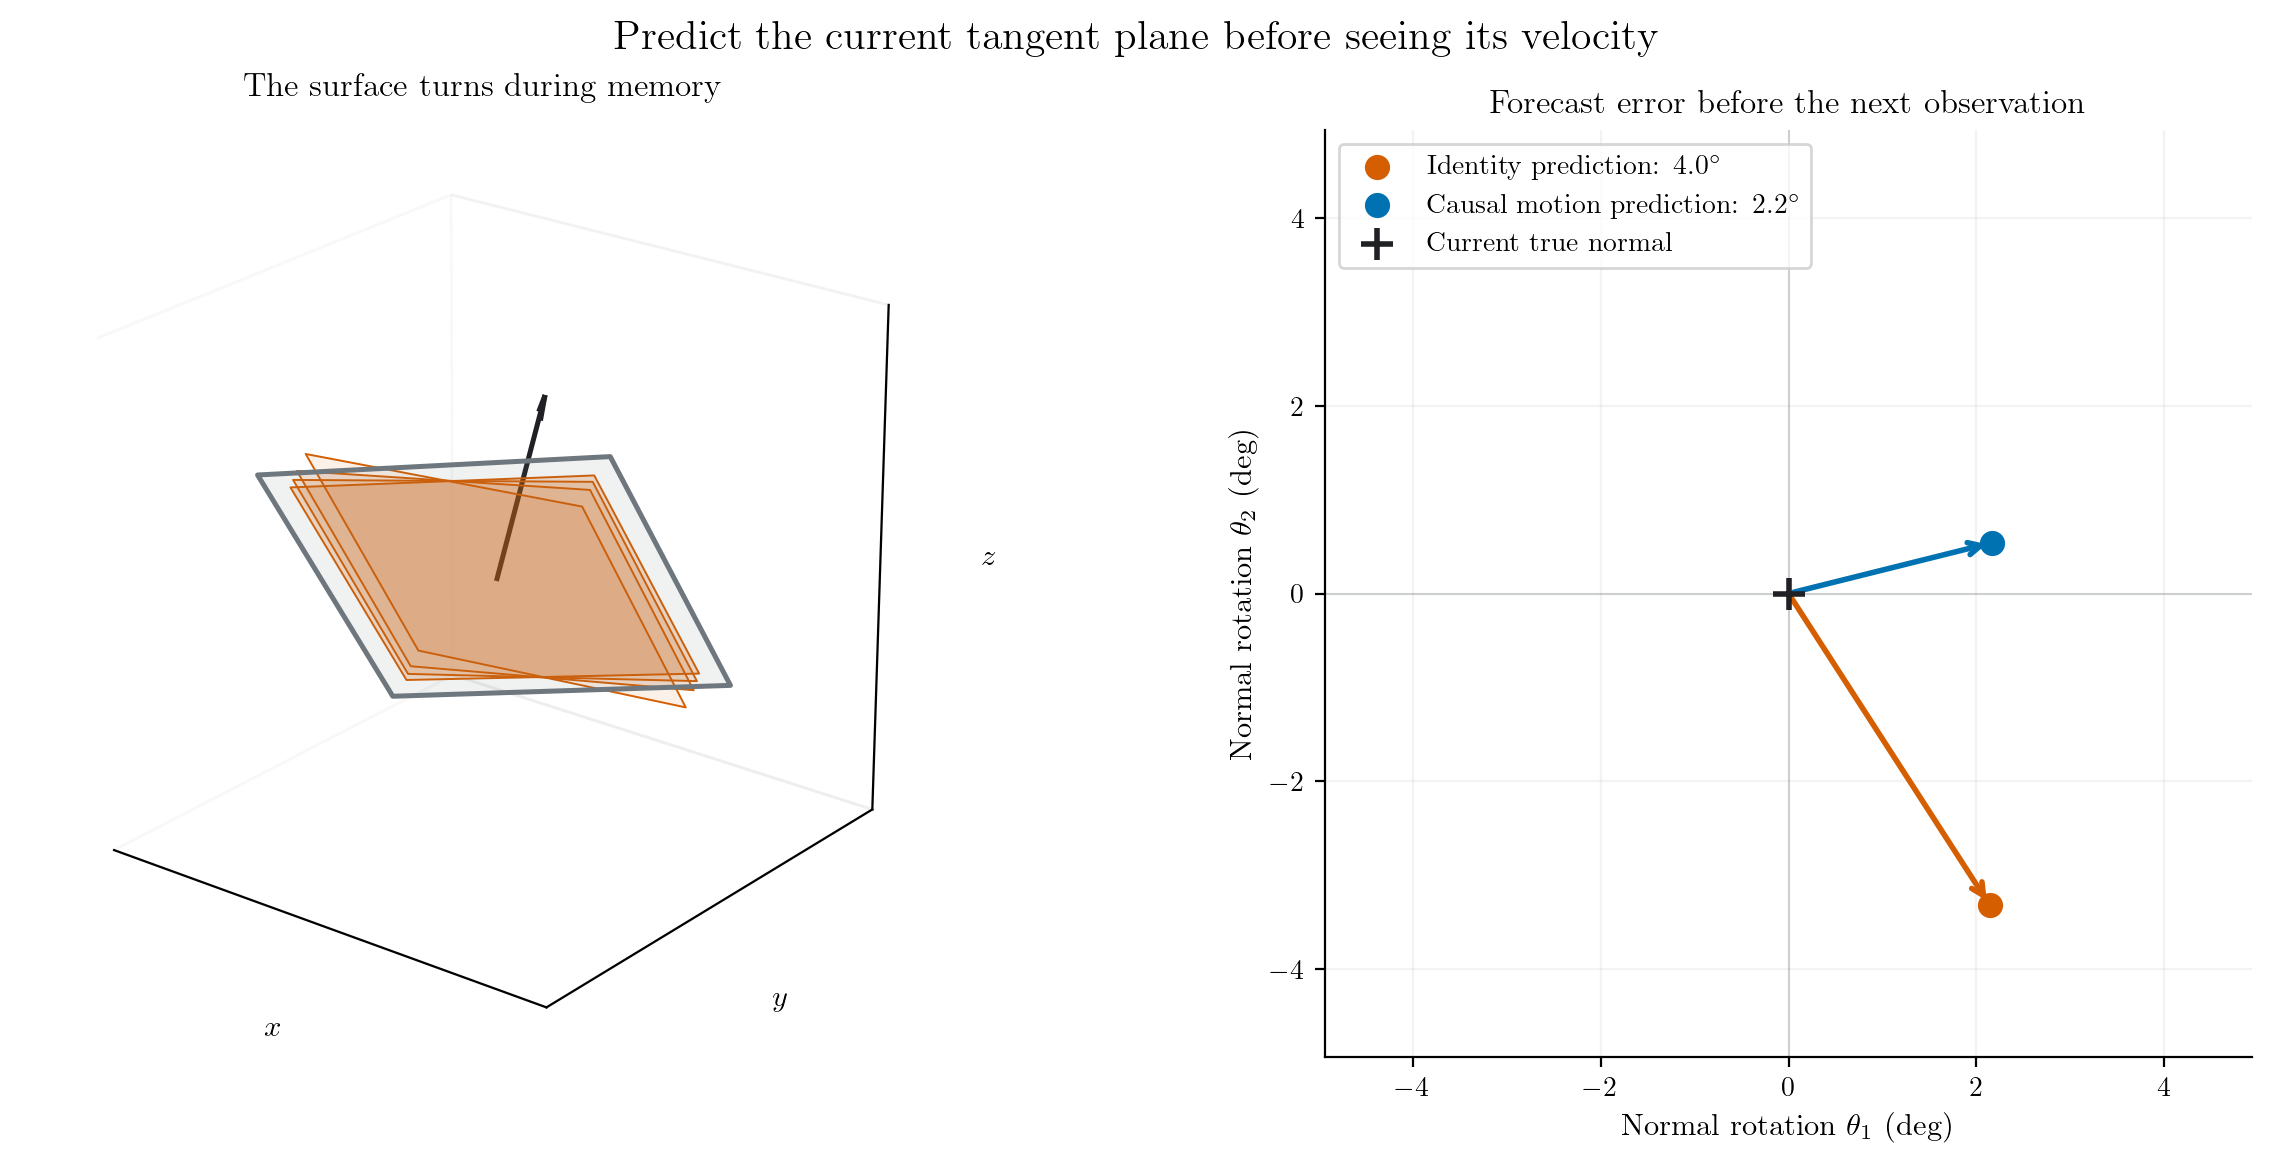

In [5]:
from lib.contact_tracking import replay
motion_spec = next(p['specification'] for p in frozen['selected']
    if p['scope'] == 'curved' and p['family'] == 'velocity')
motion = replay(cfg, data, motion_spec, audit=False)
identity_spec = next(p['specification'] for p in frozen['selected']
    if p['scope'] == 'curved' and p['family'] == 'identity')
identity = replay(cfg, data, identity_spec, audit=False)
def modal_planes(parameters):
    normals = np.linalg.eigh(parameters)[1][:, :, 0]
    return np.eye(3) - np.einsum('ti,tj->tij', normals, normals)
forecast_planes = modal_planes(motion['prior'])
show(tracking_scene(data, motion['mode_projectors'], forecast_planes, j,
    baseline_forecasts=modal_planes(identity['prior']),
    path=OUT / 'figures/02_tracking'))


A good forecast can reduce lag; estimating motion from noisy planes can also increase error. We therefore validate exponential memory, rolling windows and the causal forecast before choosing a policy. This improvement, if present, belongs to the motion model and is available to point estimators too.

## 4. From uncertain planes to uncertain velocities

The distribution is $q_A(P)\propto\exp\{\mathrm{tr}(AP)\}$. Rather than return only its mode, we map each plausible plane through one fixed test force $dw$:
$$P\longmapsto Pw,\qquad \widehat u(w)=\mathrm E[P]w.$$
This predicts a **counterfactual response at the current contact**. It is not a forecast of a later contact position. The expected response minimizes posterior squared prediction loss. For $M=\mathrm E[P]$, its posterior vector uncertainty has the exact form
$$\mathrm E_q\|Pw-Mw\|^2=w^\top(M-M^2)w.$$
This is uncertainty under the maintained distribution, not a guarantee that repeated physical errors equal it. Since $M$ is generally full rank, it is not itself a feasible contact projector or a guaranteed admissible command.

We first use a validation-selected temperature $T$: reporting $q_{A/T}$ changes spread while preserving the modal plane. This is a calibration control, not a new estimate of sensor noise.

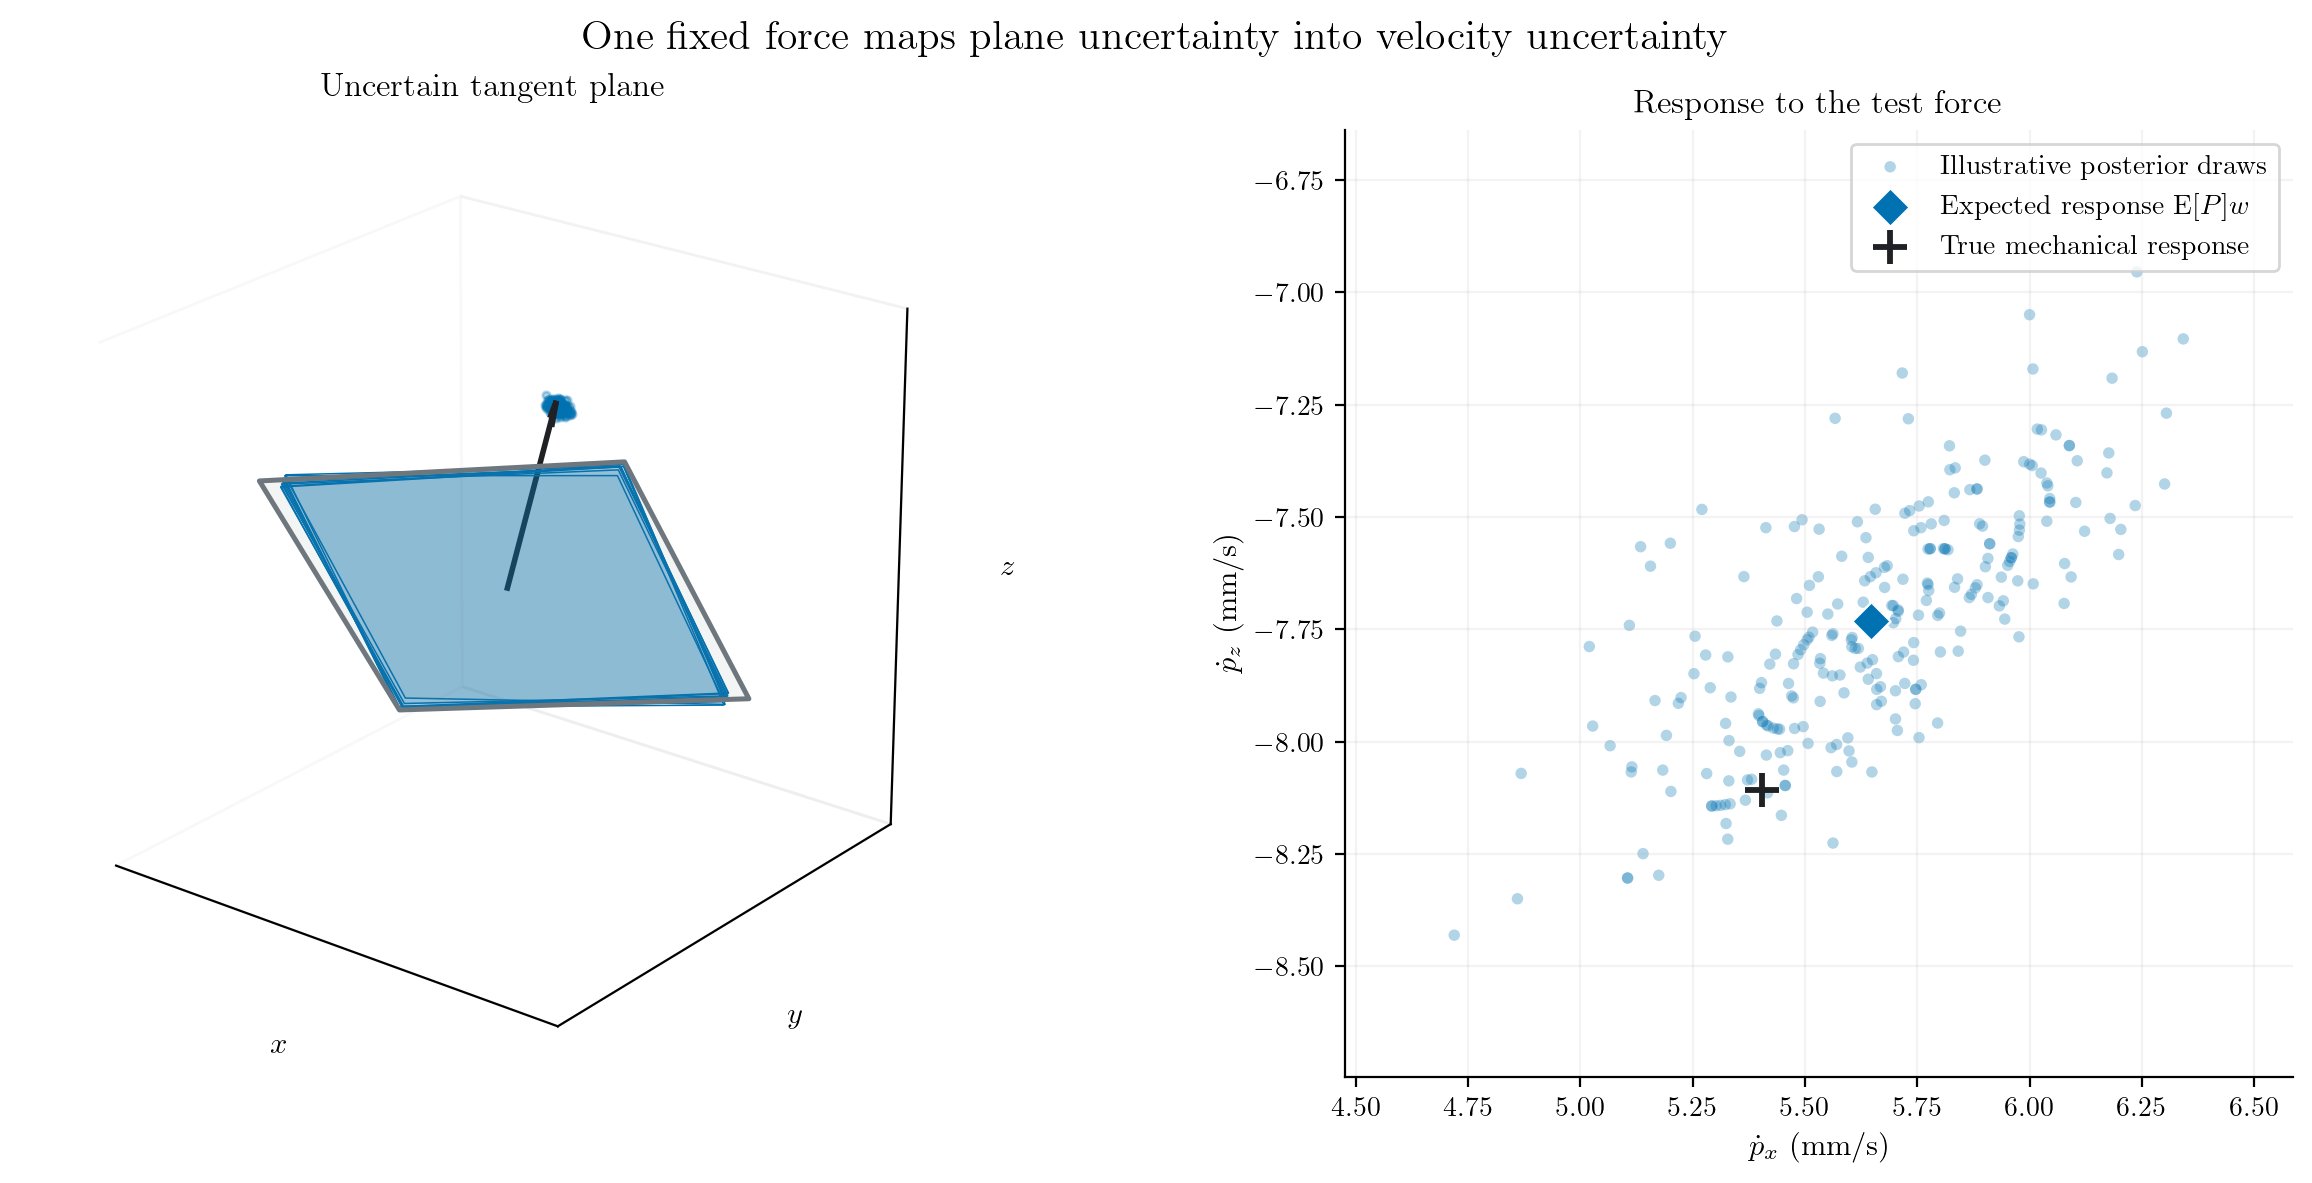

In [6]:
from lib.contact_study import query_vectors
from lib.contact_posterior import contact_summary
uncertainty = json.loads((OUT / 'uncertainty/selected.json').read_text())
temperature = next(p['temperature'] for p in uncertainty['selected']
    if p['scope'] == 'curved' and p['method'] == 'temperature')
W = query_vectors(cfg['v0'])
w = W[1]                              # Fixed force along the world y axis.
A = parameters[j] / temperature
summary = contact_summary(A, W[[1]], true_normal=data['normals'][j])
expected_velocity = summary['mean'] @ w
show(posterior_scene(data, j, A, w, expected_velocity,
    path=OUT / 'figures/03_plane_to_response'))


The blue cloud illustrates possible clean responses induced by possible planes. Its points are visualization samples; **the cloud is not a joint 95% region**. Reported scalar intervals use the checked continuous-CDF calculations, rather than sample minima and maxima. The black cross is the true response and remains visible even when the posterior misses it. The right panel shows two physical velocity components, enlarged by its labelled axis limits.

## 5. Does uncertainty follow the remaining error?

Temperature is chosen by a proper interval score on validation data: the score penalizes wide intervals and misses. This selection uses clean validation responses supplied by the simulator, rather than information available during a test trajectory. A real calibration exercise would need corresponding reference measurements. Coverage alone can be improved trivially by making everything wide.

Temperature preserves the raw modal plane while changing its distribution and possibly its expected response. It checks how much simple spread calibration already explains.

We now compare two ways to propagate uncertainty between observations. The **Bingham process filter** lets the next normal turn randomly around the nominally rotated normal. Its transition concentration controls that angular step: larger concentration means smaller random turns. It then fits a Bingham density to the exact predicted first moment. Matching the mean does not make the whole predicted density exact. The physical sphere does not follow this isotropic transition law; it is an assumed prediction model. The **Gaussian filter** tracks two local normal-rotation coordinates, with covariance transport and a kernel-matched process covariance.

Both filters receive the same causal nominal rotations and fixed sensor noise. Their process spread is tuned independently by pre-correction predictive log score, which uses observed force and velocity rather than clean validation truth. Below they predict the response to the same force after each current observation. Both rows show the same preassigned trajectory and query/component ($w=0.02e_y$ m/s, response component $x$).

To make the uncertainty visible, we subtract the true response **for plotting only**. The blue point is prediction error and the band is the predicted interval shifted by the same amount. **Zero outside the blue band marks a miss.** Estimators never receive this scoring truth. Clean intervals describe $Pw$, without adding sensor noise. Twenty fixed reporting times are shown; the shaded interpolation does not establish continuous-path or simultaneous coverage.

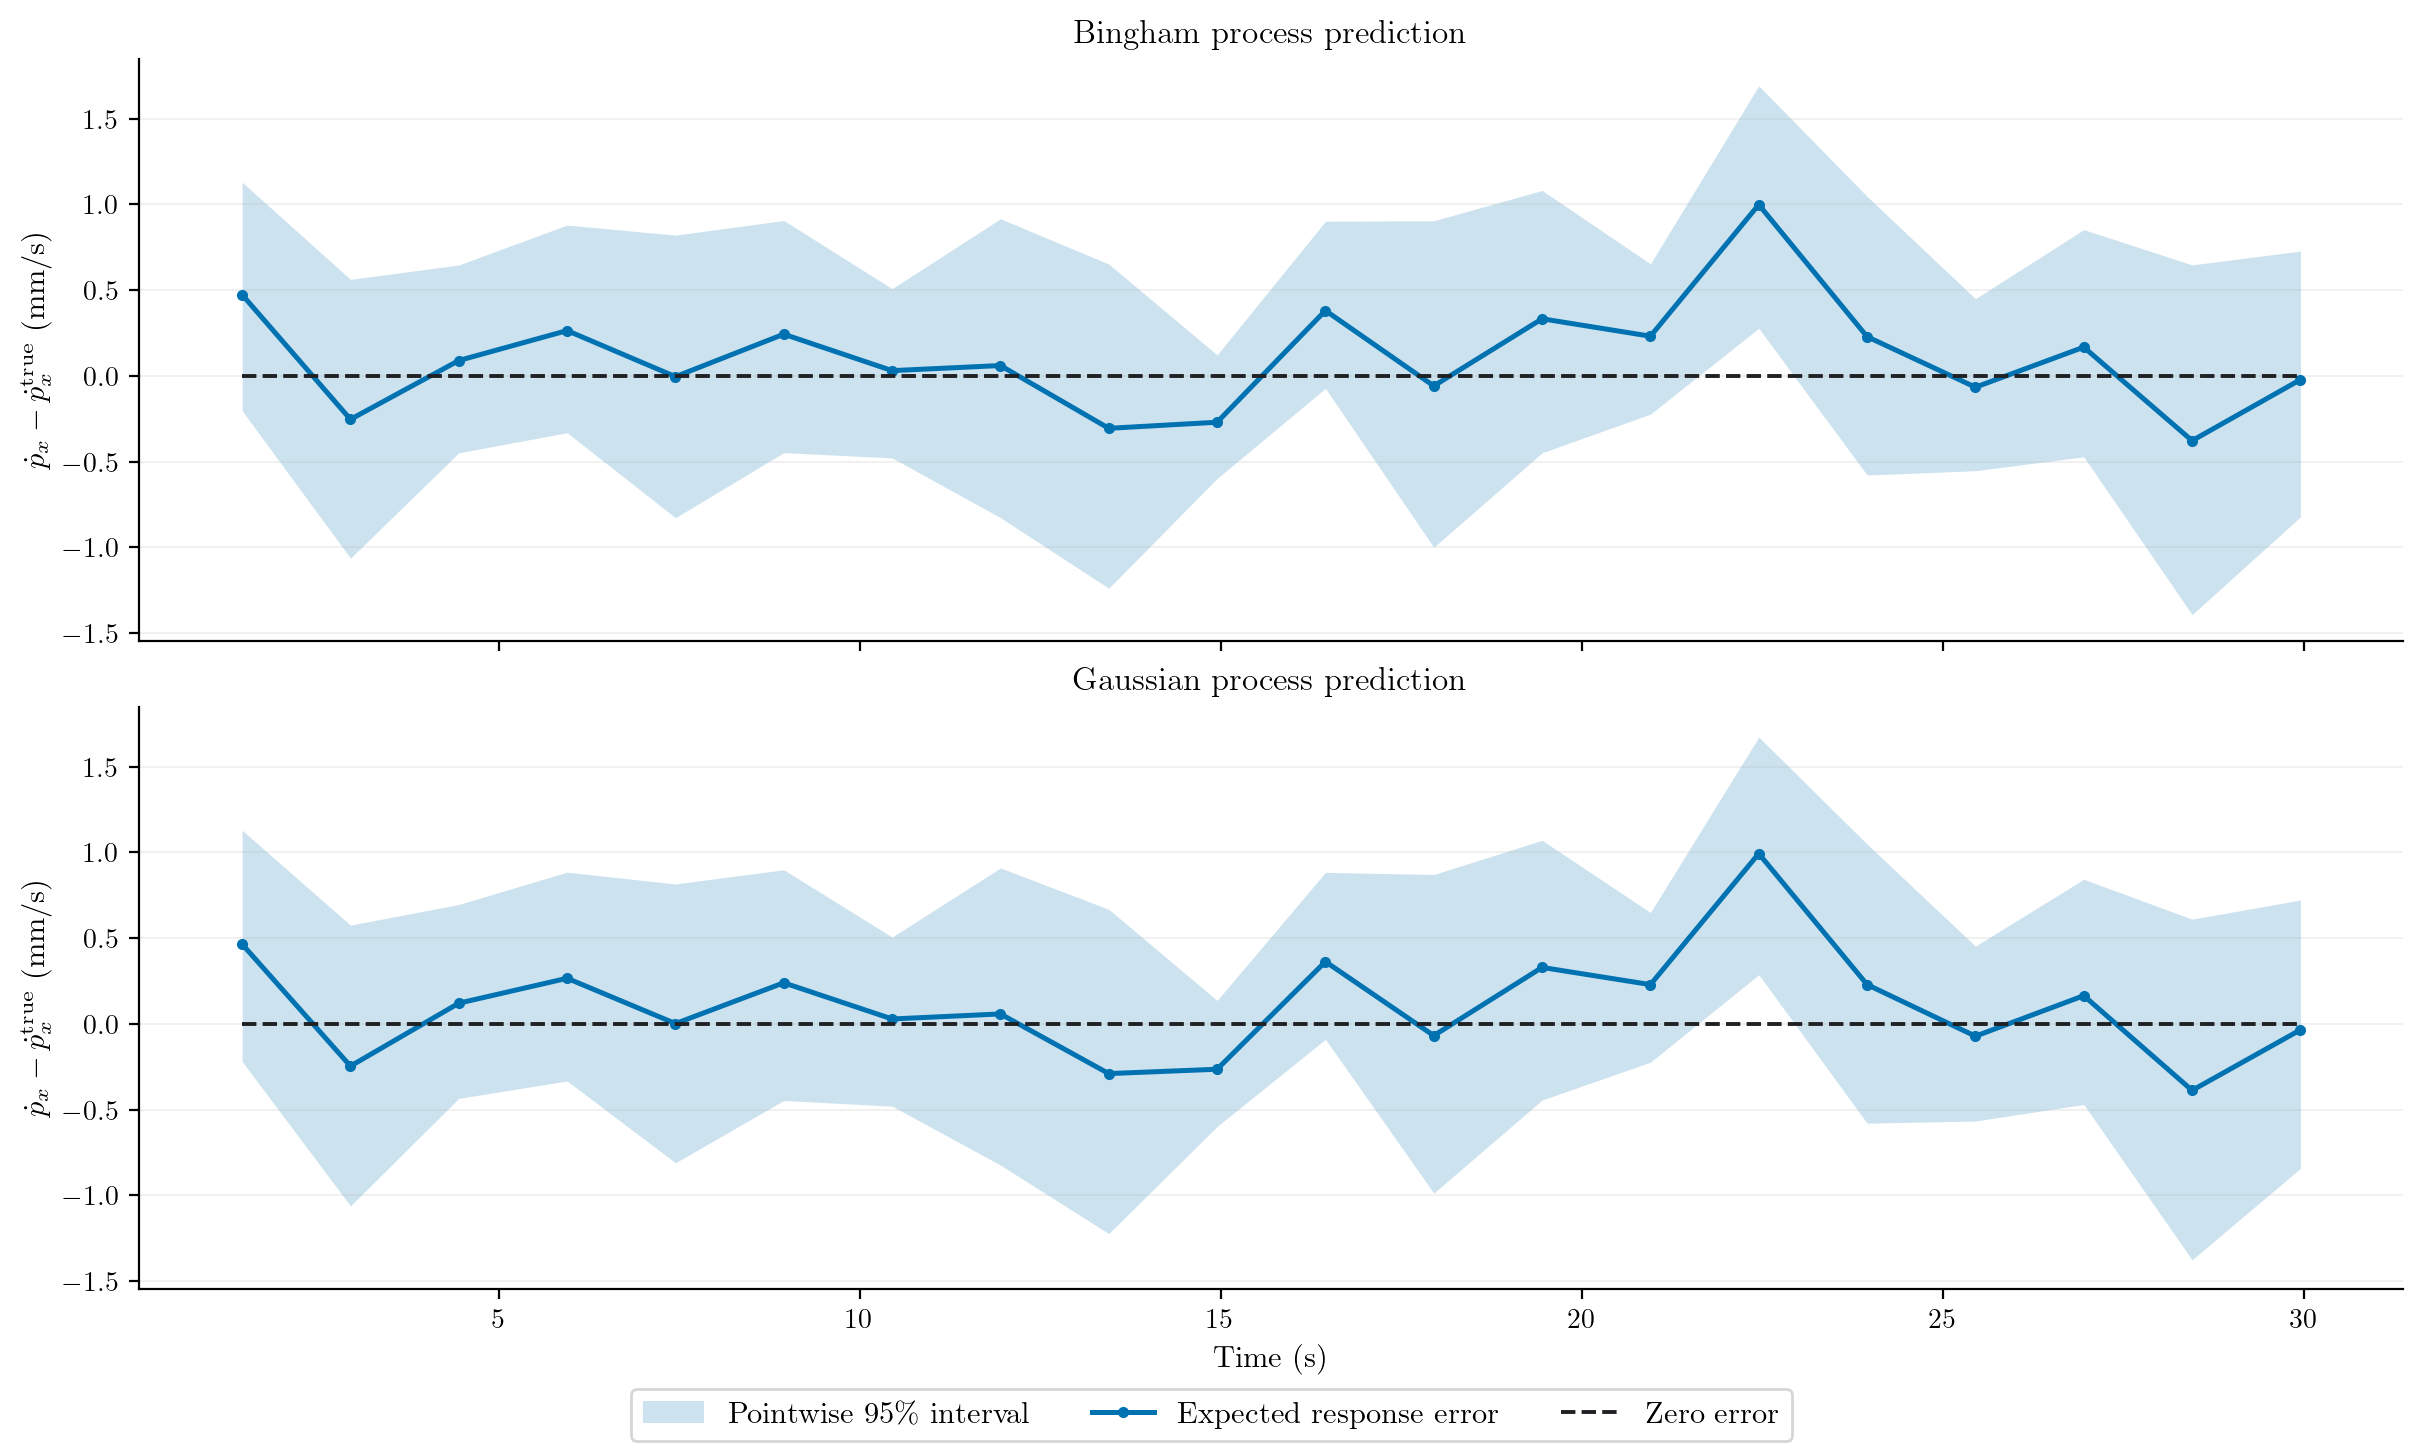

In [7]:
story = pd.read_csv(OUT / 'uncertainty/story.csv')
bands = {}
for method, label in [('process_motion', 'Bingham process prediction'),
    ('gaussian_motion', 'Gaussian process prediction')]:
    g = story.query("condition == 'sphere_small' and component == 0 and method == @method").sort_values('t')
    assert len(g) == 20 and g.interval_ok.all(), 'An unresolved interval must be reviewed.'
    bands[label] = dict(times=(g.t.to_numpy()-1)*cfg['dt'],
        **{k:g[k].to_numpy() for k in ['truth', 'mean', 'lower', 'upper']})
show(response_comparison(bands, component='x', center_on_truth=True,
    path=OUT / 'figures/04_uncertainty'))


A Gaussian approximation to each *same Bingham parameter* separately checks whether global distribution shape matters. It changes only reporting. The recursive Gaussian shown above also approximates process propagation and the nonlinear measurement update. Their full comparison therefore tests more than density shape alone.

## 6. Does the explanation survive other trajectories?

Each dot below is one of 64 independent small-sphere trajectories. The horizontal coordinate is the prediction loss of the validation-regularized point estimate, $\rho\widehat P w$; $\rho$ is fitted on validation data under the improved practical memory/forecast. The vertical coordinate is loss of a distribution's expected response. Below the diagonal means lower error than that point prediction.

The nine query losses are averaged within a trajectory. They do not provide nine independent replications. The causal forecast is shared between the Bingham and Gaussian process filters, so a difference between those two includes their propagation and measurement approximations. Their comparison alone does not isolate distribution shape.

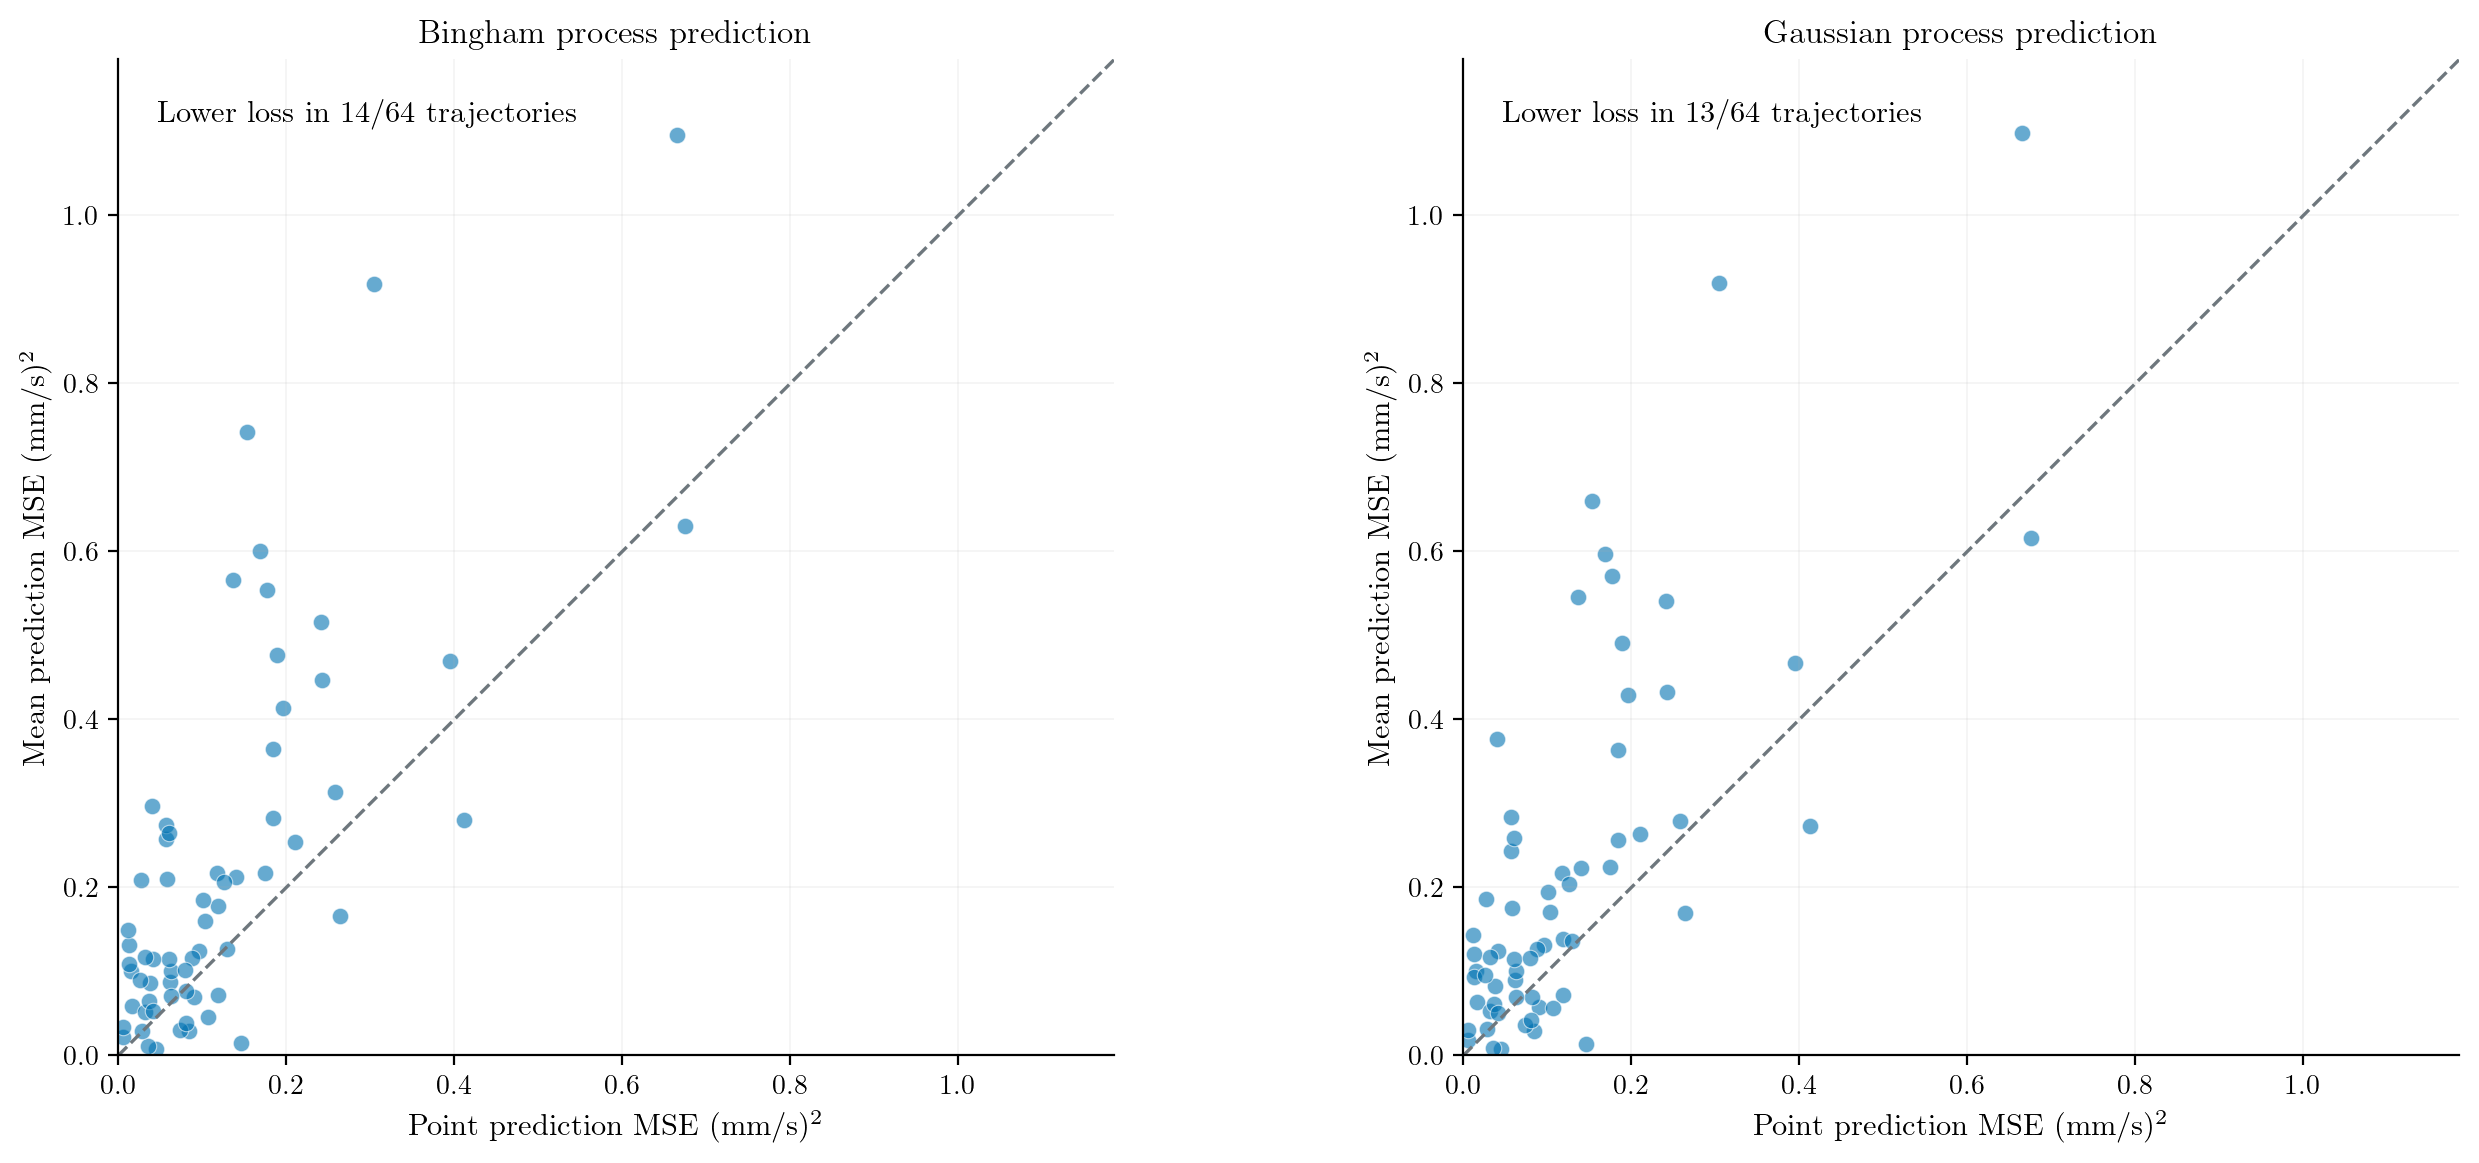

In [8]:
metrics = pd.read_csv(OUT / 'uncertainty/metrics.csv')
point = metrics[metrics.method == 'temperature'].copy()
point['method'], point['loss'] = 'point', point.regularized_mse
predictions = metrics[metrics.method.isin(['process_motion', 'gaussian_motion'])].copy()
predictions['loss'] = predictions.clean_mse
comparison = pd.concat([point, predictions], ignore_index=True)
show(paired_prediction_errors(comparison, 'point', ['process_motion', 'gaussian_motion'],
    value='loss', reference_value='loss', labels={'process_motion':'Bingham process prediction',
        'gaussian_motion':'Gaussian process prediction'}, path=OUT / 'figures/05_monte_carlo'))


In [9]:
display(Markdown((OUT / 'notebook_interpretation.md').read_text()))

The comparison is paired across **64 independent small-sphere trajectories**. Positive paired gains below mean lower loss for the Bingham process prediction; intervals are pointwise 95% Student intervals.

| Question | Held-out result |
| --- | --- |
| Does the causal forecast reduce lag? | Terminal mode MSE changes from 1.085 to 0.126 (mm/s)², a 88.4% reduction. Time-average MSE improves 43.0%. These gains are available to point methods. |
| What does spread calibration change? | With T=2, clean coverage changes from 98.0% to 100.0%; width from 0.938 to 1.326 mm/s; interval score from 0.979 to 1.326 mm/s (lower is better). The mode is unchanged. |
| Does process Bingham beat the cheap Gaussian? | It has no resolved terminal MSE advantage. The Gaussian-minus-Bingham paired MSE difference is -0.001381 [-0.006124, 0.003362] (mm/s)² (-0.62% of Gaussian loss). |
| What does computation cost? | Measured filter cost, including the common forecast tracker, is 2.38 versus 2.05 ms/observation. One 27-component uncertainty report averages 145 versus 73 ms. |

For uncertainty, Bingham/Gaussian clean-component coverage is **99.5%/99.5%**, with mean interval width **1.395/1.392 mm/s** and interval score **1.405/1.402 mm/s** (lower is better). The paired Gaussian-minus-Bingham score difference is -0.0028 [-0.0081, 0.0026] mm/s. Lower MSE alone would not establish better uncertainty.

The whole-trajectory tradeoff differs from the terminal result: time-average MSE is 1.162 for the raw forecast, 0.578 for process Bingham and 0.600 (mm/s)² for the Gaussian. Point memory was selected for terminal MSE, so this is a secondary comparison of the retained policies, not a search for the best possible time-average point estimator. Temperature was fitted on the curved-condition validation mixture; more coverage on this one endpoint can mean unnecessarily wide intervals.

An exploratory case shows where process uncertainty is useful: when the second and third force components are divided by five, the temperature control covers 94.8% at width 2.12 mm/s. Process Bingham gives 95.4% at 1.71 mm/s; the Gaussian gives 95.5% at 1.69 mm/s. Useful uncertainty propagation is supported there, while the full Bingham family still has no demonstrated premium over the Gaussian.

Time-average loss, same-parameter Gaussian checks, all misses and the other contact conditions are in the [full findings](../results/contact_tracking/findings.md). Cost scope: median of three separate serial runs of preassigned small-sphere trajectory 0; shared forecast included. Average report cost does not guarantee a 50 ms deadline. These numbers separate improved dynamics from any additional benefit of a distribution. The finite validation scan selected a lag of 32 at the extended boundary; it does not establish a globally optimal forecast.


## Scope and further checks

The stationary plane, both sphere radii and the force program with **most force along one axis** are retained. In that last condition the second and third force components are divided by five; this does not by itself prove poor information about the normal. Actual rotation, retained input and local Fisher eigenvalues are recorded.

The anisotropic-resistance stress uses $D=d\,\mathrm{diag}(1,1.5,2)$. Its actual KKT response generally differs from $P(F/d)$, so it violates the observation law. Neither broader intervals nor a better motion forecast repairs that likelihood mismatch. No practical comparison with a position/kinematics-based normal estimator is claimed: positions were deliberately withheld from every learner here.

Taking $G_t=I$ is a valid reference-frame choice for the deterministic modal bound, which includes residual drift and may have an uninformative sufficient condition. That bound does not guarantee posterior coverage on arbitrary moving contacts. Learned forecasts, fitted temperatures and approximate stochastic prediction do not inherit its fixed-frame assumptions.

**Why these benchmarks?** A force-aware projector regression and an equally informed Gaussian directly test the proposed contribution. A passive subspace method such as GROUSE solves a different observation problem; comparing against it alone could credit uncertainty for merely using the known applied force.

For a seven-joint arm, one regular contact constraint gives $\mathrm{Gr}(6,7)$; adding three fixed-orientation constraints gives a structured $\mathrm{Gr}(3,7)$ problem. Increasing dimension does not fix missing contact dynamics. The bounded [feasibility check](../results/contact_tracking/feasibility/findings.md) leaves seven of eight cases unresolved at its fixed sampling budget; general-rank process fitting remains unsupported. This identifies validation work before an arm simulation, rather than proving larger budgets infeasible. A physical extension would also require shared noisy encoders, known kinematics, and a structured null-space comparator.

### Supporting evidence and reproduction

- [Study findings](../results/contact_tracking/findings.md): paired effects, calibration, cost and the scope decision.
- [Mean tracking](../results/contact_tracking/mean/findings.md): noisy/noiseless controls, original memory and oracle diagnostic.
- [Uncertainty comparison](../results/contact_uncertainty/findings.md): process model versus distribution family, numerical limits and reporting frequency.
- [Protocol and commands](../docs/contact_tracking.md), [frozen mean policies](../results/contact_tracking/mean/selected.json), [frozen uncertainty policies](../results/contact_tracking/uncertainty/selected.json).
- [Matched-process control](../results/contact_uncertainty/matched/summary.csv): a separate dimensionless process with known spread and an independently refined full-density reference. It is not the mechanical sphere law.
- [All per-trajectory metrics](../results/contact_tracking/uncertainty/metrics.csv), [paired contrasts](../results/contact_tracking/uncertainty/paired.csv), [shape checks](../results/contact_tracking/uncertainty/shape_comparison.csv), [directional checks](../results/contact_tracking/uncertainty/directional.csv).
- [Archived original notebook](../results/contact_tracking/archive/03_contact_f09d3fe.ipynb). Other notebooks, old simulation outputs and manuscript files are unchanged.

The cells above replay one trajectory. The Monte Carlo runs are reproducible scripts with frozen validation and held-out seeds; opening this notebook does not silently launch a full benchmark. Every displayed/exported figure uses TeX, 200 dpi and the same physical units.